# Lesson 4.7: Practice Exercise

**Analyst:** John Ko
**Date:** 11/16/26

In [1]:
# Import libraries
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Set options
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

# Load files need for this practice
cohort_churn = pd.read_csv(
    'cohort-churn-by-signup-month.csv'
)

# Preparation for Panel 2
cohort_tier_breakdown = pd.read_csv(
    'cohort-by-tier-breakdown.csv', 
    header=[0, 1],
    index_col=0,
    skiprows=[2]
)

cohort_tier_breakdown.index.name = 'signup_cohort'

cohort_tier_wide = cohort_tier_breakdown['churn_rate_pct']
cohort_tier_wide.columns.name = None

# Melt back to long format
cohort_tier_long = (cohort_tier_wide.reset_index().melt(
    id_vars="signup_cohort",
    var_name="marketing_name",
    value_name="churn_rate_pct")
)

# Preparation for Panel 3
cohort_churn['signup_smoothed'] = cohort_churn['customer_count'].rolling(window=3).mean()

# Check if loaded properly
print(f"Columns: {cohort_churn.shape[1]}")
print(f"Columns: {cohort_tier_breakdown.shape[1]}")
cohort_tier_long.head(5)

Columns: 5
Columns: 6


,signup_cohort,marketing_name,churn_rate_pct
0,2024-01,Enterprise Plus,21.93
1,2024-02,Enterprise Plus,20.08
2,2024-03,Enterprise Plus,23.14
3,2024-04,Enterprise Plus,20.52
4,2024-05,Enterprise Plus,18.31


In [2]:
# Create a four-panel deck 
deck = make_subplots(
    rows=2, cols=2,
    subplot_titles=[
        'Churn rate by signup cohort.',
        'Churn rate by signup cohort and tier.',
        'Monthly signups with smoothed trend.',
        'Churn rate distribution by tier',
    ],
)

# Create a deck full of charts

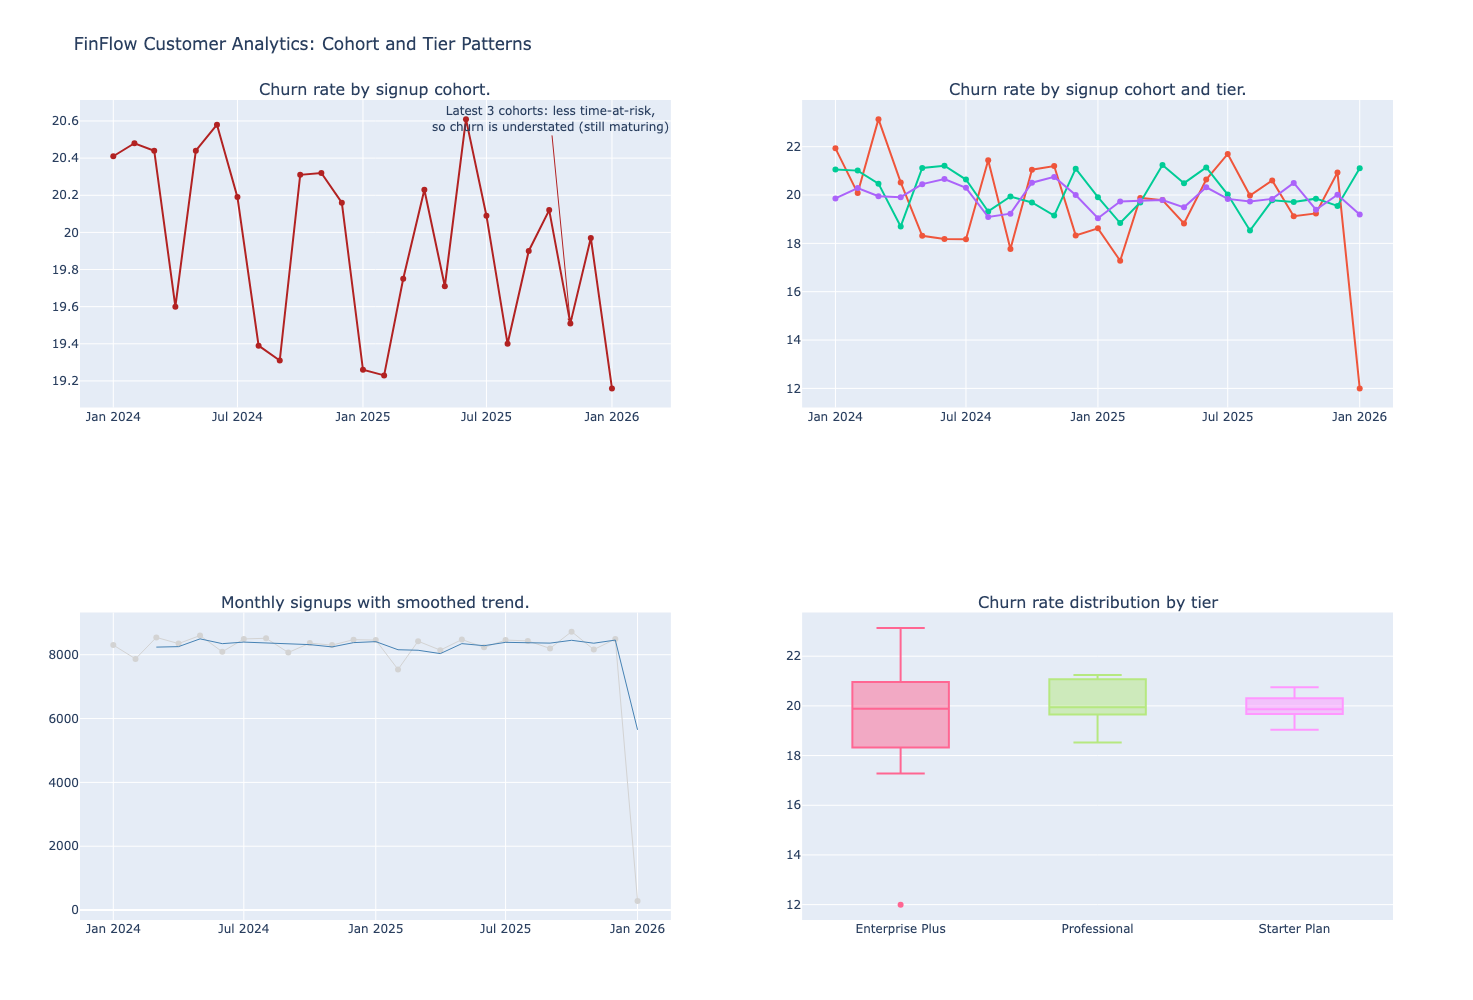

In [3]:
# Chart 1: Scatter
deck.add_trace(
    go.Scatter( x=cohort_churn["signup_cohort"], y=cohort_churn["churn_rate_pct"],
    mode="lines+markers", name="Overall churn",
    line=dict(color="firebrick"), marker=dict(color="firebrick"), showlegend=False
), row=1, col=1)

deck.add_annotation(
    x=cohort_churn["signup_cohort"].iloc[-3], y=cohort_churn["churn_rate_pct"].iloc[-3],
    ax=-20, ay=-205,
    text="Latest 3 cohorts: less time-at-risk,<br>so churn is understated (still maturing)",
    showarrow=True, arrowhead=2, arrowcolor="firebrick"
)

# Chart 2: Cohort-by-tier breakdown
for tier, grp in cohort_tier_long.groupby("marketing_name"):
    deck.add_trace(go.Scatter(
        x=grp["signup_cohort"], y=grp["churn_rate_pct"],
        mode="lines+markers", name=tier,
    ), row=1, col=2
)

# Chart 3: Monthly signup trend with smoothing.
deck.add_trace(
    go.Scatter( x=cohort_churn["signup_cohort"], y=cohort_churn["customer_count"],
    mode="lines+markers", name="tier",
    line=dict(color="lightgray", width=1)
), row=2, col=1)

deck.add_trace(go.Scatter(
    x=cohort_churn['signup_cohort'],
    y=cohort_churn['signup_smoothed'],
    mode='lines',
    name='3-month rolling avg',
    line=dict(color='steelblue', width=1)
), row=2, col=1)

# Chart 4
for tier, grp in cohort_tier_long.groupby("marketing_name"):
    deck.add_trace(go.Box(
        y=grp["churn_rate_pct"], name=tier,
        showlegend=False,
    ), row=2, col=2)

deck.update_layout(
    title_text='FinFlow Customer Analytics: Cohort and Tier Patterns',
    height=1000,
    showlegend=False
)

## Justification for chart #4
Use box plot to show how spread out each tier's churn rate is with the Enterprise the most spread out.

In [4]:
deck.write_html("finflow-friday-deck-final.html")
print("finflow-friday-deck-final.html saved")

finflow-friday-deck-final.html saved


Across all four panels, FinFlow’s churn is flat at about 20% in every cohort and every tier, and signups hold steady near 8,300 a month. Any outlier is noise or artifact. The dip in the latest cohorts is the time is not enough to gather all the necessary data, the Enterprise Plus swings come from its small cohort sizes, and the drop at the end of the signup chart is the partial 2026-01 month. The question for product leadership is: if churn is about 20% regardless of plan or signup month, has there been any events or outliers that may have suggest otherwise, if so any evidence?